In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
df = pd.read_csv('../WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
).fillna(0)

X = df.drop(columns=["customerID", "Churn"])
y = pd.Series((df["Churn"] == "Yes").astype(int), name="churn")

print(y.value_counts())
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", np.array(["No Churn", "Churn"]))

churn
0    5174
1    1869
Name: count, dtype: int64
Feature matrix shape: (7043, 19)
Target shape: (7043,)
Class names: ['No Churn' 'Churn']


In [4]:
class_counts = y.value_counts().sort_index()
class_distribution = pd.DataFrame(
    {
        "Class": ["No Churn", "Churn"],
        "Count": class_counts.values,
        "Probability": class_counts.values / len(y),
    }
)

print(class_distribution)

      Class  Count  Probability
0  No Churn   5174      0.73463
1     Churn   1869      0.26537


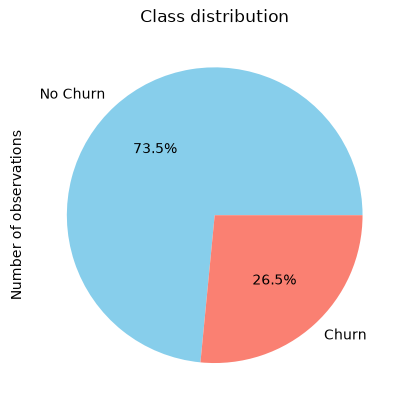

In [5]:
class_distribution.plot(
    x="Class",
    y="Count",
    kind="pie",
    labels=class_distribution["Class"],
    autopct="%1.1f%%",
    legend=False,
    colors=["skyblue", "salmon"],
)

plt.ylabel("Number of observations")
plt.title("Class distribution")
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training size:", len(y_train))
print("Testing size:", len(y_test))

print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training size: 5634
Testing size: 1409

Training proportions:
churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing proportions:
churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [7]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    col for col in X.columns if col not in numeric_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(drop="first", sparse_output=False),
            categorical_features,
        ),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "logisticregression",
            LogisticRegression(max_iter=1000, random_state=42),
        ),
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [8]:
probabilities = model.predict_proba(X_test)
print(probabilities[:5])

[[0.9535867  0.0464133 ]
 [0.31580675 0.68419325]
 [0.9396986  0.0603014 ]
 [0.60140726 0.39859274]
 [0.97816829 0.02183171]]


In [9]:
results = pd.DataFrame(
    {
        "Actual_class": y_test.values,
        "P_NoChurn": probabilities[:, 0],
        "P_Churn": probabilities[:, 1],
    }
)

print(results.head(10))

   Actual_class  P_NoChurn   P_Churn
0             0   0.953587  0.046413
1             0   0.315807  0.684193
2             0   0.939699  0.060301
3             0   0.601407  0.398593
4             0   0.978168  0.021832
5             0   0.396488  0.603512
6             0   0.554124  0.445876
7             0   0.871257  0.128743
8             0   0.997099  0.002901
9             1   0.604269  0.395731


In [10]:
results["Actual_label"] = results["Actual_class"].map(
    {0: "No Churn", 1: "Churn"}
)

print(results[["Actual_label", "P_NoChurn", "P_Churn"]].head(10))

  Actual_label  P_NoChurn   P_Churn
0     No Churn   0.953587  0.046413
1     No Churn   0.315807  0.684193
2     No Churn   0.939699  0.060301
3     No Churn   0.601407  0.398593
4     No Churn   0.978168  0.021832
5     No Churn   0.396488  0.603512
6     No Churn   0.554124  0.445876
7     No Churn   0.871257  0.128743
8     No Churn   0.997099  0.002901
9        Churn   0.604269  0.395731


In [11]:
threshold = 0.50

results["Predicted_churn"] = (results["P_Churn"] >= threshold).astype(int)

results["Predicted_label"] = results["Predicted_churn"].map(
    {1: "Churn", 0: "No Churn"}
)

print(results[["Actual_label", "P_Churn", "Predicted_label"]].head(10))

  Actual_label   P_Churn Predicted_label
0     No Churn  0.046413        No Churn
1     No Churn  0.684193           Churn
2     No Churn  0.060301        No Churn
3     No Churn  0.398593        No Churn
4     No Churn  0.021832        No Churn
5     No Churn  0.603512           Churn
6     No Churn  0.445876        No Churn
7     No Churn  0.128743        No Churn
8     No Churn  0.002901        No Churn
9        Churn  0.395731        No Churn


In [12]:
for threshold in [0.20, 0.30, 0.50, 0.70]:
    predictions = (results["P_Churn"] >= threshold).astype(int)
    print(
        f"threshold = {threshold}: Predicted churn cases = {predictions.sum()}"
    )

threshold = 0.2: Predicted churn cases = 685
threshold = 0.3: Predicted churn cases = 544
threshold = 0.5: Predicted churn cases = 317
threshold = 0.7: Predicted churn cases = 94


In [13]:
actual_churn = y_test.values

for threshold in [0.20, 0.30, 0.50, 0.70]:
    predicted_churn = (probabilities[:, 1] >= threshold).astype(int)
    cm = confusion_matrix(actual_churn, predicted_churn)

    print(f"\nThreshold = {threshold}")
    print(cm)


Threshold = 0.2
[[670 365]
 [ 54 320]]

Threshold = 0.3
[[774 261]
 [ 91 283]]

Threshold = 0.5
[[927 108]
 [165 209]]

Threshold = 0.7
[[1011   24]
 [ 304   70]]


In [14]:
y_pred = model.predict(X_test)

print("Sklearn accuracy:", accuracy_score(y_test, y_pred))
print("Sklearn precision:", precision_score(y_test, y_pred))
print("Sklearn recall:", recall_score(y_test, y_pred))
print("Sklearn f1-score:", f1_score(y_test, y_pred))

Sklearn accuracy: 0.8062455642299503
Sklearn precision: 0.6593059936908517
Sklearn recall: 0.5588235294117647
Sklearn f1-score: 0.6049204052098408


In [15]:
threshold_metrics = pd.DataFrame(
    columns=[
        "threshold",
        "TN",
        "FP",
        "FN",
        "TP",
        "accuracy",
        "precision",
        "sensitivity_recall",
        "f1-score",
    ]
)

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:
    # Prediction using threshold on churn probability
    predicted_churn = (probabilities[:, 1] >= threshold).astype(int)

    # Confusion matrix
    cm = confusion_matrix(actual_churn, predicted_churn)
    TN, FP, FN, TP = cm.ravel()

    # Manual formulas
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    precision = TP / (TP + FP) if (TP + FP) != 0 else 0
    sensitivity_recall = TP / (TP + FN) if (TP + FN) != 0 else 0
    f1 = (
        2
        * precision
        * sensitivity_recall
        / (precision + sensitivity_recall)
        if (precision + sensitivity_recall) != 0
        else 0
    )

    threshold_metrics.loc[len(threshold_metrics)] = [
        threshold,
        TN,
        FP,
        FN,
        TP,
        accuracy,
        precision,
        sensitivity_recall,
        f1,
    ]

display(threshold_metrics.round(3))

,threshold,TN,FP,FN,TP,accuracy,precision,sensitivity_recall,f1-score
0,0.1,515.0,520.0,20.0,354.0,0.617,0.405,0.947,0.567
1,0.3,774.0,261.0,91.0,283.0,0.750,0.520,0.757,0.617
2,0.5,927.0,108.0,165.0,209.0,0.806,0.659,0.559,0.605
3,0.7,1011.0,24.0,304.0,70.0,0.767,0.745,0.187,0.299
4,0.9,1035.0,0.0,374.0,0.0,0.735,0.000,0.000,0.000
